# FFS – Fast FITS Statistics

1. **Quick** – FWHM klatki jednym wywołaniem (tak jak w ofp i TOI).
2. **Pełny przebieg** – maski, tło, linie, gwiazdy, mapy PSF, zapis do FITS.
3. **Klatki kalibracyjne** – złe kolumny i piksele z master zero, użycie na klatce naukowej.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # pyaraucaria z tego repozytorium
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from pyaraucaria.ffs import FFS

DATA = os.path.expanduser("~/work/data/fits_examples")
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"

def show(ax, img, title="", lo=1, hi=99.5, cmap="gray"):
    vmin, vmax = np.nanpercentile(img, [lo, hi])
    ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax, origin="lower", interpolation="nearest")
    ax.set_title(title)

def overlay(ax, mask, color, label):
    rgba = np.zeros(mask.shape + (4,))
    rgba[mask] = plt.matplotlib.colors.to_rgba(color, 0.8)
    ax.imshow(rgba, origin="lower", interpolation="nearest")
    ax.plot([], [], "s", color=color, label=f"{label} ({mask.sum()} px)")

---
## 1. Quick: FWHM klatki

`calc_frame_fwhm()` robi cały przebieg (maski, tło, linie, gwiazdy) i zwraca mediany z najjaśniejszych
dobrych gwiazd w `stats["frame"]`. Gdy gwiazd jest za mało, wartości to `NaN`.
Dla dużych klatek (> ~2500 px) dodaj `autobin=True`.

In [2]:
image = fits.getdata(os.path.join(DATA, "zb08c_0612_72902.fits"))

ffs = FFS(image, saturation=60000)
ffs.calc_frame_fwhm(N_stars=50)

for key in ("fwhm", "fwhm_x", "fwhm_y", "ellipticity", "used_stars"):
    print(f"{key:12s} {ffs.stats['frame'][key]:8.3f}   {ffs.stats_description['frame'][key]}")

fwhm            3.904   Median of the full width at half maximum (FWHM) of the brightest sources in the frame
fwhm_x          3.927   Median FWHM measured along the X axis
fwhm_y          3.998   Median FWHM measured along the Y axis
ellipticity     0.097   Median source ellipticity (1 − b/a), describing PSF elongation
used_stars     50.000   How many star were used to evaluate thos statistics


`ffs.stars` ma wszystkie wykryte gwiazdy; te, których nie mierzono (saturowane, poza `N_stars`,
ze złymi pikselami w pudełku), mają `NaN` w kolumnach pomiarów.

In [3]:
ffs.stars["x", "y", "max_adu", "fwhm", "ellipticity"][:8]

x,y,max_adu,fwhm,ellipticity
int64,int64,float64,float64,float64
1435,1408,32615.0,3.929293552831965,0.1134764900328592
885,1026,17212.0,nan,nan
622,742,5718.0,3.4921287146156135,0.10898604236415654
730,240,5707.0,3.82518171538792,0.11236862777410017
358,1521,5183.0,4.01577064884296,0.050517647267123045
318,99,4249.0,3.6517936640630237,0.028614041409076196
958,1472,4155.0,4.312034388840518,0.06096323852001351
676,443,3695.0,3.624346774487239,0.0667328626643291


---
## 2. Pełny przebieg

Te same kroki co w `calc_frame_fwhm()`, po kolei, plus maska gwiazd, mapy PSF i zapis.
Każda metoda ma parametr `exclude` – listę masek, których piksele pomija (domyślne listy: `FFS.EXCLUDE_*`).

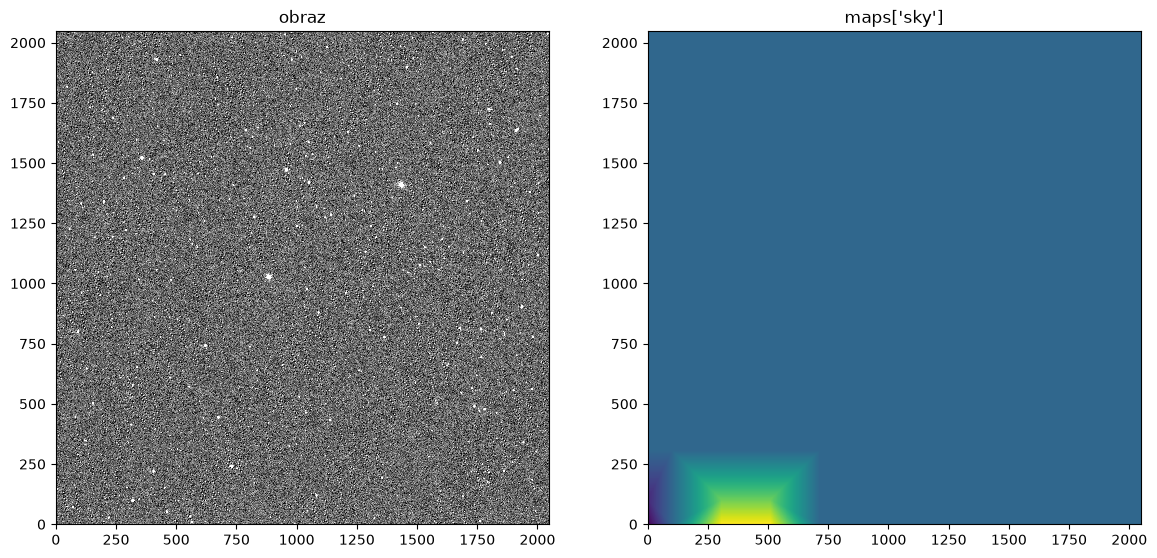

{'median': 303.0, 'q_sigma': 7.5, 'bkg_max_amplitude': 0.34, 'bkg_frame_gradient': 0.82}


In [4]:
ffs = FFS(image, saturation=60000)
ffs.mk_saturation_mask()     # masks["saturation"]
ffs.mk_stats()               # stats["frame"]: min, max, median, rms, q_sigma, noise
ffs.sky_map()                # maps["sky"]; stats["frame"]: bkg_max_amplitude, bkg_frame_gradient
ffs.mk_cosmics_mask()        # masks["cosmics"]
ffs.mk_threshold_mask()      # masks["threshold"]: piksele > tlo + 3 sigma

fig, axs = plt.subplots(1, 2, figsize=(14, 6.5))
show(axs[0], image, "obraz")
show(axs[1], ffs.maps["sky"], "maps['sky']", lo=0, hi=100, cmap="viridis")
plt.show()
print({k: round(float(ffs.stats["frame"][k]), 2) for k in ("median", "q_sigma", "bkg_max_amplitude", "bkg_frame_gradient")})

### Linie i gwiazdy

`find_lines()` – transformata Hougha; głosują tylko piksele „liniowe” (test pierścienia, `ring_radius`),
odcinki sprawdzane są na pełnej masce progowej. `classify_lines()` oddziela promienie jasnych gwiazd
(`masks["spikes"]`) od satelitów (`masks["lines"]`).

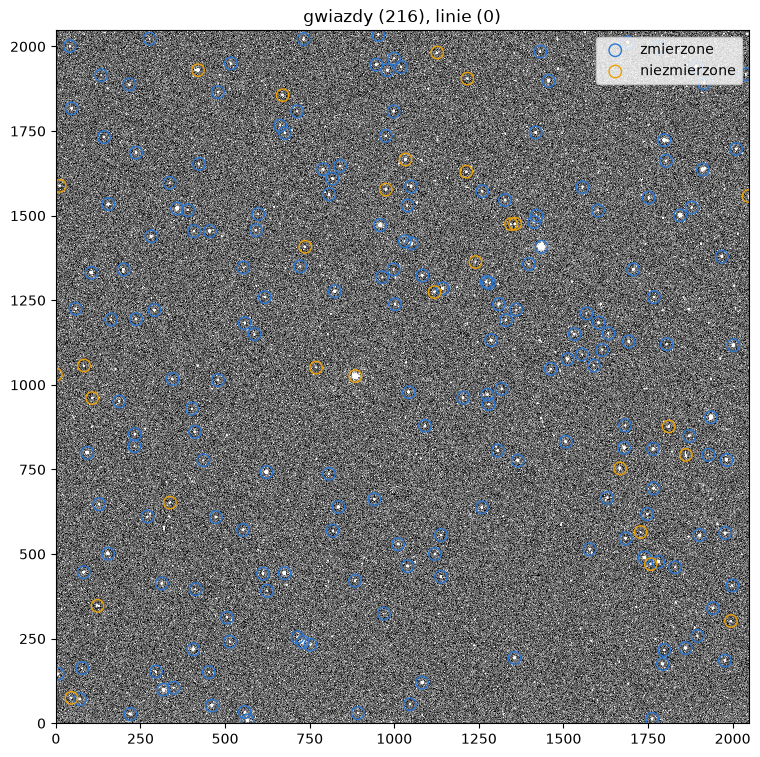

FWHM 3.98 px, eliptycznosc 0.127, z 184 gwiazd


In [5]:
ffs.find_lines()
ffs.classify_lines()
ffs.find_stars(threshold=10, fwhm=10)
ffs.star_info(box=10, N_stars=None)
ffs.calc_star_stats()

fig, ax = plt.subplots(figsize=(9, 9))
show(ax, image, f"gwiazdy ({len(ffs.coo)}), linie ({len(ffs.lines)})")
ok = np.isfinite(ffs.fwhm)
ax.scatter(ffs.coo[ok, 1], ffs.coo[ok, 0], s=80, facecolors="none", edgecolors=C1, label="zmierzone")
ax.scatter(ffs.coo[~ok, 1], ffs.coo[~ok, 0], s=80, facecolors="none", edgecolors=C4, label="niezmierzone")
for name, color in (("lines", C2), ("spikes", C3), ("saturation", C4)):
    if ffs.masks[name].any():
        overlay(ax, ffs.masks[name], color, name)
ax.legend(loc="upper right")
plt.show()
print(f"FWHM {ffs.frame_fwhm:.2f} px, eliptycznosc {ffs.frame_ellipticity:.3f}, z {ffs.frame_used_stars} gwiazd")

### Maska gwiazd i drugi przebieg statystyk

`mk_stars_mask(k=3)` – koła o promieniu k·FWHM wokół wszystkich detekcji. Maska `"stars"` jest w
`FFS.SOURCES`, więc statystyki i tło ją pomijają, a detekcja i pomiar gwiazd – nie.

In [6]:
before = {k: ffs.stats["frame"][k] for k in ("n_excluded", "mean", "rms")}
ffs.mk_stars_mask(k=3)
ffs.mk_stats()
ffs.sky_map()
for k, v in before.items():
    print(f"{k:5s} {v:10.2f} -> {ffs.stats['frame'][k]:10.2f}")

n_excluded       0.00 ->   94551.00
mean      303.90 ->     303.17
rms        64.49 ->       7.97


### Mapy gwiazd i statystyki pola

`mk_star_maps()` – mapy FWHM, eliptyczności, kąta i gęstości gwiazd (średnia ważona Gaussem, bez modelu)
oraz tabela `psf_grid` do „wąsów”. `calc_star_field_stats()` – globalne wzorce: wspólne wydłużenie,
wzorzec styczny/radialny (`psf_e_t`), wir (`psf_e_x`), tilt i krzywizna FWHM.

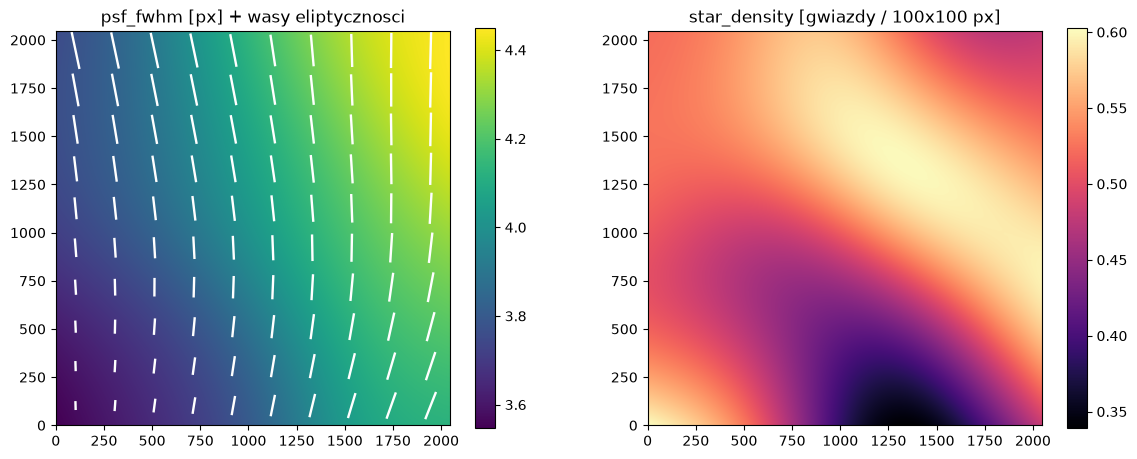

psf_e_mean         0.087   Common elongation hypot(mean e1, mean e2) (tracking, wind)
psf_e_t            0.006   Mean tangential ellipticity around the frame centre (> 0 tangential, < 0 radial)
psf_e_x            0.003   Mean cross ellipticity around the frame centre (45 deg swirl)
psf_fwhm_tilt      0.991   FWHM change across the frame from a linear + r^2 fit (px per frame)
psf_fwhm_curv     -0.077   FWHM change from the frame centre to a corner, r^2 term (px)


In [7]:
ffs.mk_star_maps()
ffs.calc_star_field_stats()

g = ffs.psf_grid
fig, axs = plt.subplots(1, 2, figsize=(14, 6.5))
im = axs[0].imshow(ffs.maps["psf_fwhm"], origin="lower", cmap="viridis")
fig.colorbar(im, ax=axs[0], shrink=0.8)
L = 1500 * np.asarray(g["ellipticity"])          # dlugosc wasa ~ eliptycznosc
axs[0].quiver(g["x"], g["y"], L * np.cos(g["theta"]), L * np.sin(g["theta"]), color="w",
              headwidth=0, headlength=0, headaxislength=0, pivot="mid", angles="xy", scale_units="xy", scale=1)
axs[0].set_title("psf_fwhm [px] + wasy eliptycznosci")
im = axs[1].imshow(ffs.maps["star_density"], origin="lower", cmap="magma")
fig.colorbar(im, ax=axs[1], shrink=0.8)
axs[1].set_title("star_density [gwiazdy / 100x100 px]")
plt.show()
for k in ("psf_e_mean", "psf_e_t", "psf_e_x", "psf_fwhm_tilt", "psf_fwhm_curv"):
    print(f"{k:15s} {ffs.stats['frame'][k]:8.3f}   {ffs.stats_description['frame'][k]}")

### Zapis

`save_mef()` zapisuje wszystko do jednego pliku FITS: nagłówek z kluczami `FF*`, mapy, maski jako jedna
maska bitowa (`MASKS`, bit i = `MASKi` z nagłówka) i tabele.

In [8]:
import tempfile
path = os.path.join(tempfile.gettempdir(), "zb08c_0612_72902_ffs.fits")
ffs.save_mef(path, header=fits.getheader(os.path.join(DATA, "zb08c_0612_72902.fits")), overwrite=True)
fits.info(path)

Filename: /var/folders/d1/n39w6bbs3f1_3tml2k1fftww0000gn/T/zb08c_0612_72902_ffs.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      74   ()      
  1  SKY           1 ImageHDU        10   (2048, 2048)   float32   
  2  PSF_FWHM      1 ImageHDU        10   (2048, 2048)   float32   
  3  PSF_ELLIPTICITY    1 ImageHDU        10   (2048, 2048)   float32   
  4  PSF_THETA     1 ImageHDU        10   (2048, 2048)   float32   
  5  PSF_WEIGHT    1 ImageHDU        10   (2048, 2048)   float32   
  6  STAR_DENSITY    1 ImageHDU        10   (2048, 2048)   float32   
  7  MASKS         1 ImageHDU        14   (2048, 2048)   int32   
  8  STARS         1 BinTableHDU     35   216R x 13C   [K, K, D, D, D, D, D, D, D, D, D, D, D]   
  9  LINES         1 BinTableHDU     31   0R x 11C   [D, D, D, D, D, D, D, D, D, D, D]   
 10  SKYSURF       1 BinTableHDU     15   100R x 3C   [K, K, D]   
 11  PSFGRID       1 BinTableHDU     23   100R x 7C   [D, D, D, D,

---
## 3. Klatki kalibracyjne

Maski defektów robimy na **master zero** (mediana kilku zer): mapa w ADU, potem maska z progiem.

| mapa | maska |
|---|---|
| `mk_columns_map()` → `maps["columns"]`, `maps["rows"]` | `mk_bad_columns_mask(threshold)` → `masks["bad_columns"]`, `masks["bad_rows"]` |
| `mk_pixels_map()` → `maps["pixels"]` | `mk_hot_pixels_mask(threshold)`, `mk_cold_pixels_mask(threshold)` |

Przykład: jk15c (4096×4108, cztery wzmacniacze).

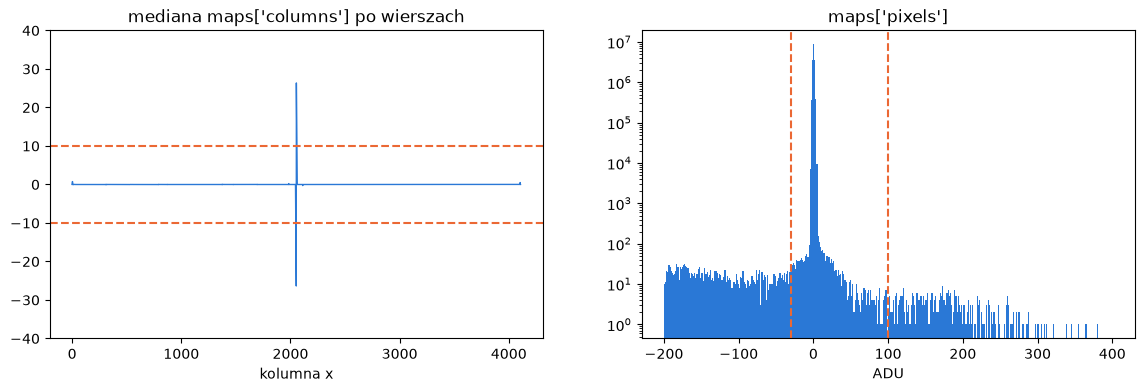

In [9]:
files = ["jk15c_0612_75680.fits", "jk15c_0655_01058.fits"]
master = np.median([fits.getdata(os.path.join(DATA, f)).astype(float) for f in files], axis=0)

cal = FFS(master)
cal.sky_map(n_segments=32)      # skok poziomu miedzy kwadrantami wymaga gestszej mapy tla
cal.mk_columns_map()
cal.mk_pixels_map()

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].plot(np.median(cal.maps["columns"], axis=0), color=C1, lw=1)
axs[0].set_title("mediana maps['columns'] po wierszach"); axs[0].set_xlabel("kolumna x"); axs[0].set_ylim(-40, 40)
axs[1].hist(cal.maps["pixels"].ravel(), bins=400, range=(-200, 400), color=C1, log=True)
axs[1].set_title("maps['pixels']"); axs[1].set_xlabel("ADU")
for ax, ts in ((axs[0], (10, -10)), (axs[1], (100, -30))):
    for t in ts:
        ax.axvline(t, color=C2, ls="--") if ax is axs[1] else ax.axhline(t, color=C2, ls="--")
plt.show()

Progi w ADU odczytujemy z wykresów (przerywane linie):

In [10]:
cal.mk_bad_columns_mask(threshold=10)
cal.mk_hot_pixels_mask(threshold=100)
cal.mk_cold_pixels_mask(threshold=30)
for name in ("bad_columns", "bad_rows", "hot_pixels", "cold_pixels"):
    print(f"{name:12s} {cal.masks[name].sum():8d} px")

cal_path = os.path.join(tempfile.gettempdir(), "jk15c_master_zero_ffs.fits")
cal.save_mef(cal_path, overwrite=True)

bad_columns     25856 px
bad_rows        24712 px
hot_pixels        460 px
cold_pixels      3161 px


### Użycie na klatce naukowej

Maski czytamy z `MASKS` (nazwa bitu w nagłówku) i wpisujemy do `masks`. Nazwy `bad_columns`,
`bad_rows`, `hot_pixels`, `cold_pixels` są w `FFS.BAD_PIXELS`, więc wszystkie metody pomijają je same.
Maski kalibracyjne zawsze w rozmiarze oryginału, także przy binowaniu.

bin 2, pominiete piksele 53050, FWHM 4.28, linie 4


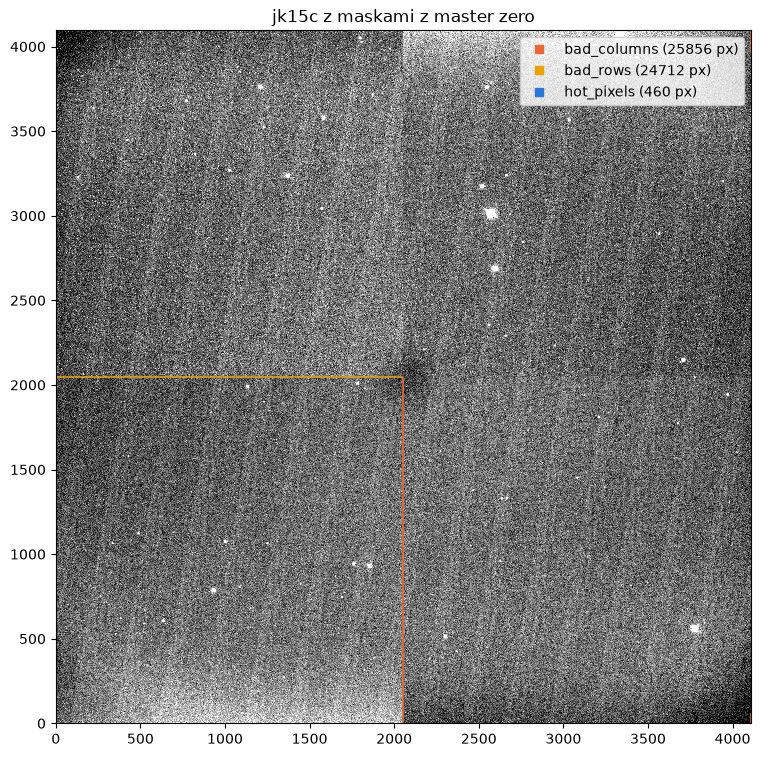

In [11]:
def load_masks(path, names):
    with fits.open(path) as hl:
        bits, h = hl["MASKS"].data, hl["MASKS"].header
        return {h[k]: (bits >> int(k[4:])) & 1 == 1 for k in h if k.startswith("MASK") and h[k] in names}

science = fits.getdata(os.path.join(DATA, "jk15c_0154_73367.fits")).astype(float)
sc = FFS(science, saturation=45000, autobin=True)
sc.masks.update(load_masks(cal_path, ("bad_columns", "bad_rows", "hot_pixels", "cold_pixels")))
sc.calc_frame_fwhm(N_stars=50)
print(f"bin {sc.bin}, pominiete piksele {sc.stats['frame']['n_excluded']}, FWHM {sc.frame_fwhm:.2f}, linie {len(sc.lines)}")

fig, ax = plt.subplots(figsize=(9, 9))
show(ax, science, "jk15c z maskami z master zero")
for name, color in (("bad_columns", C2), ("bad_rows", C4), ("hot_pixels", C1)):
    overlay(ax, sc.masks[name], color, name)
ax.legend(loc="upper right")
plt.show()